Dataset loaded successfully
Total records: 5000
Total input features: 11

Target distribution:
Genuine accounts (0): 2500
Fake accounts (1): 2500

Training records: 4000
Testing records: 1000

Genetic Algorithm progress:
Generation 01: Fitness = 0.9796, Features selected = 6
Generation 02: Fitness = 0.9796, Features selected = 6
Generation 03: Fitness = 0.9808, Features selected = 8
Generation 04: Fitness = 0.9808, Features selected = 8
Generation 05: Fitness = 0.9813, Features selected = 8
Generation 06: Fitness = 0.9816, Features selected = 8
Generation 07: Fitness = 0.9816, Features selected = 8
Generation 08: Fitness = 0.9816, Features selected = 8
Generation 09: Fitness = 0.9816, Features selected = 8
Generation 10: Fitness = 0.9816, Features selected = 8

Selected features:
- profile pic
- nums/length username
- fullname words
- nums/length fullname
- private
- #posts
- #followers
- #follows

Selected 8 out of 11 features

========== FINAL MODEL RESULTS ==========
Accuracy : 0.98

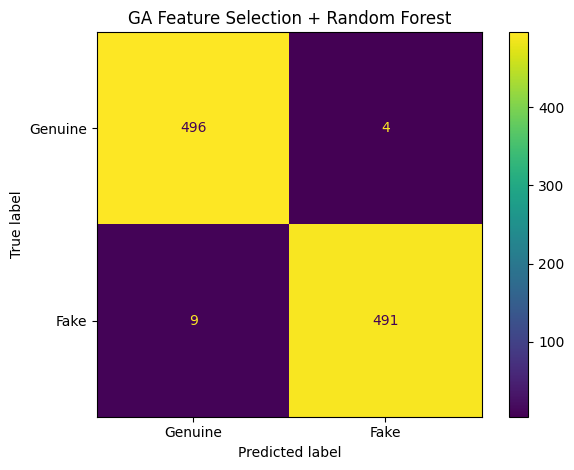


Confusion matrix saved as confusion_matrix.png


In [3]:

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

DATA_FILE = "Instagram_fake_profile_dataset.csv"
TARGET = "fake"
RANDOM_STATE = 42

# 1. Load dataset
data = pd.read_csv(DATA_FILE)
data = data.dropna().reset_index(drop=True)

X = data.drop(columns=[TARGET])
y = data[TARGET].astype(int)

X = X.apply(pd.to_numeric, errors="raise")
feature_names = X.columns.tolist()
X = X.to_numpy()

print("Dataset loaded successfully")
print("Total records:", len(data))
print("Total input features:", len(feature_names))

print("\nTarget distribution:")
print("Genuine accounts (0):", int((y == 0).sum()))
print("Fake accounts (1):", int((y == 1).sum()))

# 2. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# 3. Genetic Algorithm settings
POPULATION_SIZE = 12
GENERATIONS = 10
MUTATION_RATE = 0.10
CROSSOVER_RATE = 0.80
N_FEATURES = X_train.shape[1]

rng = random.Random(RANDOM_STATE)
fitness_cache = {}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

def repair_chromosome(chromosome):
    if sum(chromosome) == 0:
        chromosome[rng.randrange(N_FEATURES)] = 1
    return chromosome

# 4. Fitness function
def fitness(chromosome):
    chromosome = repair_chromosome(chromosome)
    key = tuple(chromosome)

    if key not in fitness_cache:
        selected = np.flatnonzero(chromosome)

        model = RandomForestClassifier(
            n_estimators=60,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            class_weight="balanced"
        )

        scores = cross_val_score(
            model,
            X_train[:, selected],
            y_train,
            cv=cv,
            scoring="accuracy",
            n_jobs=1
        )

        fitness_cache[key] = (
            scores.mean()
            - 0.003 * len(selected) / N_FEATURES
        )

    return fitness_cache[key]

# 5. Tournament selection
def tournament_selection(population):
    candidates = rng.sample(
        population,
        min(3, len(population))
    )
    return max(candidates, key=fitness).copy()

# 6. Crossover
def crossover(parent1, parent2):
    if N_FEATURES > 1 and rng.random() < CROSSOVER_RATE:
        point = rng.randint(1, N_FEATURES - 1)

        child1 = parent1[:point] + parent2[point:]
        child2 = parent2[:point] + parent1[point:]

        return (
            repair_chromosome(child1),
            repair_chromosome(child2)
        )

    return parent1.copy(), parent2.copy()

# 7. Mutation
def mutate(chromosome):
    for i in range(N_FEATURES):
        if rng.random() < MUTATION_RATE:
            chromosome[i] = 1 - chromosome[i]

    return repair_chromosome(chromosome)

# 8. Initialize population
population = [
    repair_chromosome([
        rng.randint(0, 1) for _ in range(N_FEATURES)
    ])
    for _ in range(POPULATION_SIZE)
]

print("\nGenetic Algorithm progress:")

# 9. Evolve the population
for generation in range(GENERATIONS):
    population.sort(key=fitness, reverse=True)
    best = population[0]

    print(
        f"Generation {generation + 1:02d}: "
        f"Fitness = {fitness(best):.4f}, "
        f"Features selected = {sum(best)}"
    )

    # Elitism: retain the best chromosome
    new_population = [best.copy()]

    while len(new_population) < POPULATION_SIZE:
        parent1 = tournament_selection(population)
        parent2 = tournament_selection(population)

        child1, child2 = crossover(parent1, parent2)

        new_population.append(mutate(child1))

        if len(new_population) < POPULATION_SIZE:
            new_population.append(mutate(child2))

    population = new_population

# 10. Select the best feature subset
best_chromosome = max(population, key=fitness)
selected_indices = np.flatnonzero(best_chromosome)

selected_features = [
    feature_names[i] for i in selected_indices
]

print("\nSelected features:")
for feature in selected_features:
    print("-", feature)

print(
    f"\nSelected {len(selected_features)} "
    f"out of {N_FEATURES} features"
)

# 11. Train final Random Forest
final_model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced"
)

final_model.fit(
    X_train[:, selected_indices],
    y_train
)

# 12. Predict test data
y_pred = final_model.predict(
    X_test[:, selected_indices]
)

# 13. Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, pos_label=1, zero_division=0
)
recall = recall_score(
    y_test, y_pred, pos_label=1, zero_division=0
)
f1 = f1_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

print("\n========== FINAL MODEL RESULTS ==========")
print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

# 14. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

print("\n========== CONFUSION MATRIX ==========")
print("Rows = Actual classes")
print("Columns = Predicted classes")
print("Class 0 = Genuine, Class 1 = Fake\n")

print("                 Predicted")
print("                Genuine  Fake")
print(f"Actual Genuine    {tn:4d}   {fp:4d}")
print(f"Actual Fake       {fn:4d}   {tp:4d}")

print("\n========== CONFUSION MATRIX ANALYSIS ==========")
print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)

print("\nCorrect predictions:", tn + tp)
print("Incorrect predictions:", fp + fn)
print("Total test records:", len(y_test))
print("Genuine accounts incorrectly flagged:", fp)
print("Fake accounts missed:", fn)
print("Fake accounts correctly detected:", tp)

# 15. Classification report
print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Genuine (0)", "Fake (1)"],
    zero_division=0
))

# 16. Display and save confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine", "Fake"]
)

display.plot(values_format="d")
plt.title("GA Feature Selection + Random Forest")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

print("\nConfusion matrix saved as confusion_matrix.png")
